# AirGuard AI — Air Pollution Detection & AQI Category Prediction



## 1. Install and import libraries
Run the install cell once if any package is missing.

In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import os, sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)

Python: 3.11.16
Pandas: 3.0.6


## 2. Locate and load the dataset
Place the CSV beside this notebook, or in a `dataset/` folder. You can also edit `DATA_PATH` manually.

In [2]:
candidate_paths = [
    Path("global_air_pollution_dataset.csv"),
    Path("dataset/global_air_pollution_dataset.csv"),
    Path("../global_air_pollution_dataset.csv"),
    Path("../dataset/global_air_pollution_dataset.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "CSV not found. Put global_air_pollution_dataset.csv beside this notebook "
        "or inside a dataset/ folder, then update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset:", DATA_PATH.resolve())
print("Shape:", df.shape)
display(df.head())

Dataset: D:\python\AirGuard_AI_2_0\dataset\global_air_pollution_dataset.csv
Shape: (23463, 12)


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


## 3. Understand and validate the data

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nDataset information:")
df.info()
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["AQI Category"].value_counts(dropna=False).to_frame("count"))

Column names:
['Country', 'City', 'AQI Value', 'AQI Category', 'CO AQI Value', 'CO AQI Category', 'Ozone AQI Value', 'Ozone AQI Category', 'NO2 AQI Value', 'NO2 AQI Category', 'PM2.5 AQI Value', 'PM2.5 AQI Category']

Data types:


,dtype
Country,str
City,str
AQI Value,int64
AQI Category,str
CO AQI Value,int64
CO AQI Category,str
Ozone AQI Value,int64
Ozone AQI Category,str
NO2 AQI Value,int64
NO2 AQI Category,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Country             23036 non-null  str  
 1   City                23462 non-null  str  
 2   AQI Value           23463 non-null  int64
 3   AQI Category        23463 non-null  str  
 4   CO AQI Value        23463 non-null  int64
 5   CO AQI Category     23463 non-null  str  
 6   Ozone AQI Value     23463 non-null  int64
 7   Ozone AQI Category  23463 non-null  str  
 8   NO2 AQI Value       23463 non-null  int64
 9   NO2 AQI Category    23463 non-null  str  
 10  PM2.5 AQI Value     23463 non-null  int64
 11  PM2.5 AQI Category  23463 non-null  str  
dtypes: int64(5), str(7)
memory usage: 3.2 MB

Missing values:


,missing_count
Country,427
City,1
AQI Value,0
AQI Category,0
CO AQI Value,0
CO AQI Category,0
Ozone AQI Value,0
Ozone AQI Category,0
NO2 AQI Value,0
NO2 AQI Category,0



Duplicate rows: 0

Target distribution:


,count
AQI Category,
Good,9936
Moderate,9231
Unhealthy,2227
Unhealthy for Sensitive Groups,1591
Very Unhealthy,287
Hazardous,191


## 4. Clean the dataset
Remove exact duplicate records, normalize column labels, coerce pollutant measurements to numeric, and remove rows without the target. Missing numeric predictors will be imputed inside each model pipeline (fit on training data only).

In [4]:
df = df.copy()
df.columns = df.columns.str.strip()
df = df.drop_duplicates().reset_index(drop=True)

TARGET = "AQI Category"
FEATURES = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]
required = FEATURES + [TARGET]
missing_cols = [col for col in required if col not in df.columns]
if missing_cols:
    raise ValueError(f"Required columns missing from CSV: {missing_cols}")

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df[TARGET] = df[TARGET].astype("string").str.strip()
df = df.dropna(subset=[TARGET])
df = df[df[TARGET] != ""]

print("Cleaned shape:", df.shape)
print("Missing predictor values:")
display(df[FEATURES].isna().sum().to_frame("missing_count"))
print("Target classes:", sorted(df[TARGET].unique().tolist()))

Cleaned shape: (23463, 12)
Missing predictor values:


,missing_count
CO AQI Value,0
Ozone AQI Value,0
NO2 AQI Value,0
PM2.5 AQI Value,0


Target classes: ['Good', 'Hazardous', 'Moderate', 'Unhealthy', 'Unhealthy for Sensitive Groups', 'Very Unhealthy']


## 5. Exploratory Data Analysis (EDA)

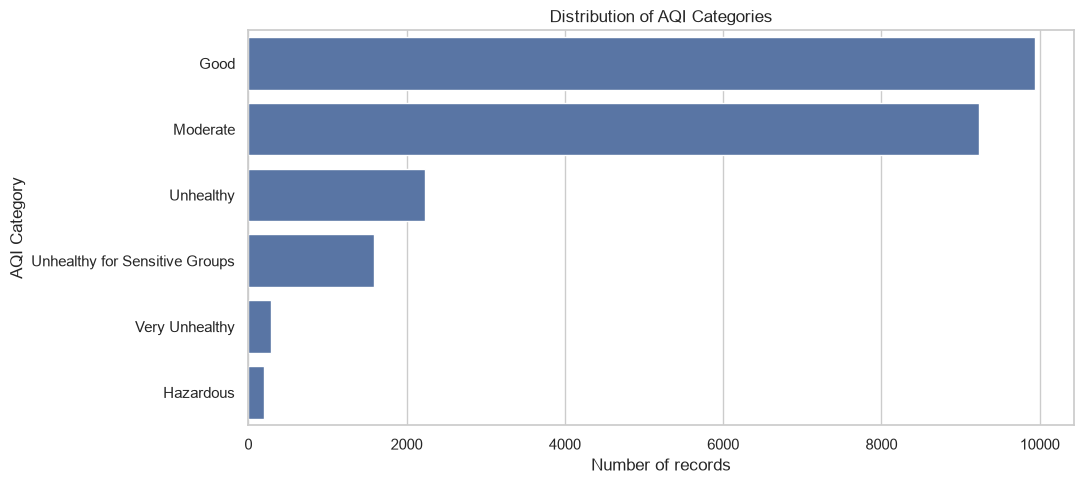

,count,mean,std,min,25%,50%,75%,max
CO AQI Value,23463.0,1.368367,1.832064,0.0,1.0,1.0,1.0,133.0
Ozone AQI Value,23463.0,35.193709,28.098723,0.0,21.0,31.0,40.0,235.0
NO2 AQI Value,23463.0,3.063334,5.254108,0.0,0.0,1.0,4.0,91.0
PM2.5 AQI Value,23463.0,68.519755,54.796443,0.0,35.0,54.0,79.0,500.0


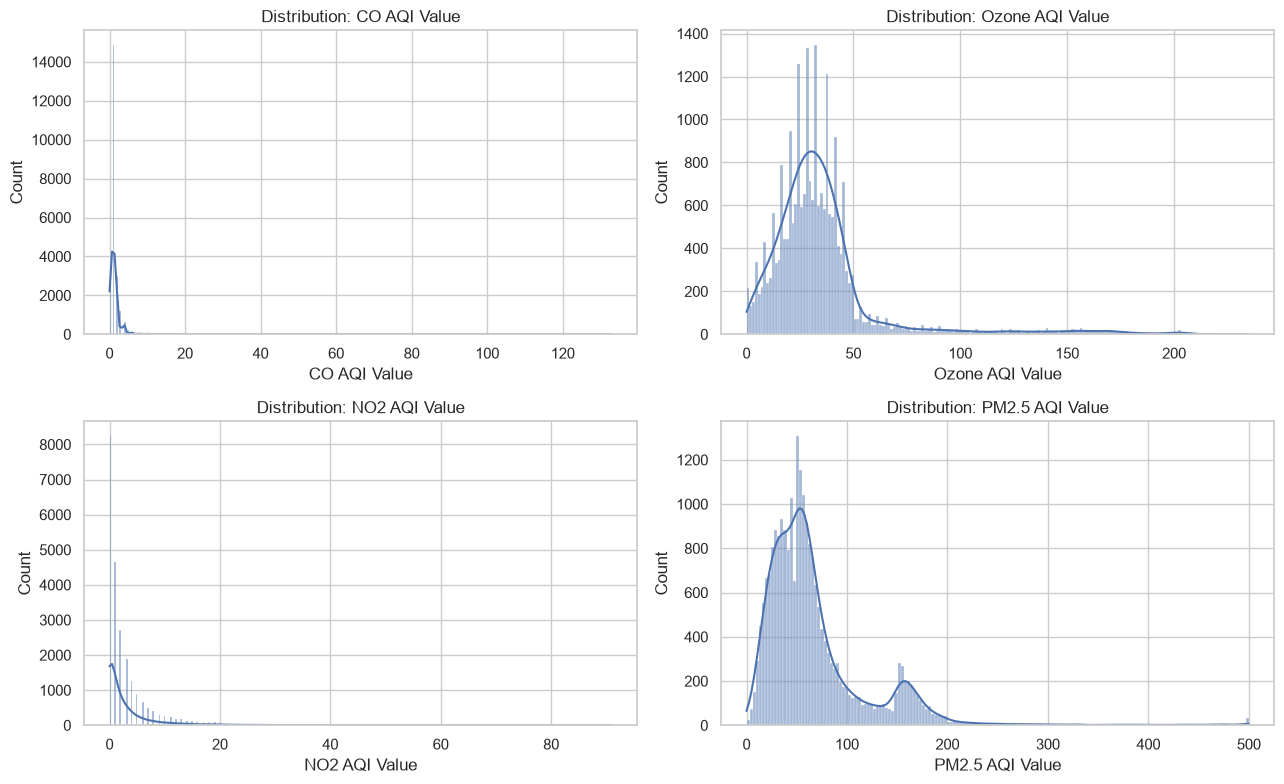

In [5]:
# Target class distribution
plt.figure(figsize=(11, 5))
order = df[TARGET].value_counts().index
sns.countplot(data=df, y=TARGET, order=order)
plt.title("Distribution of AQI Categories")
plt.xlabel("Number of records")
plt.ylabel("AQI Category")
plt.tight_layout()
plt.show()

# Summary statistics
display(df[FEATURES].describe().T)

# Pollutant distributions
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
plt.tight_layout()
plt.show()

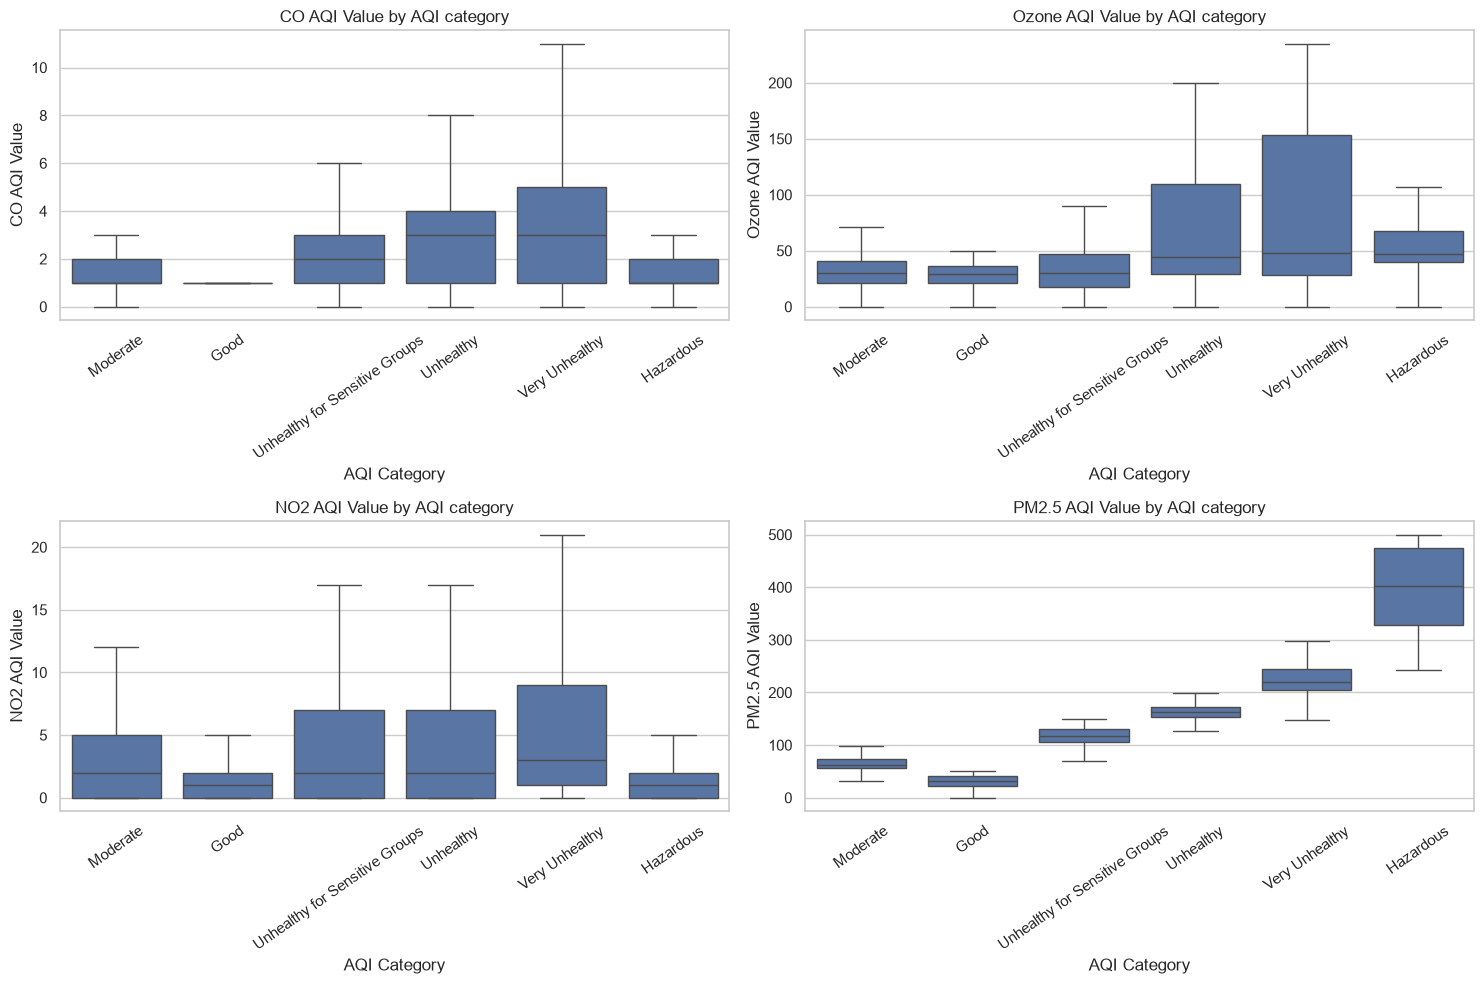

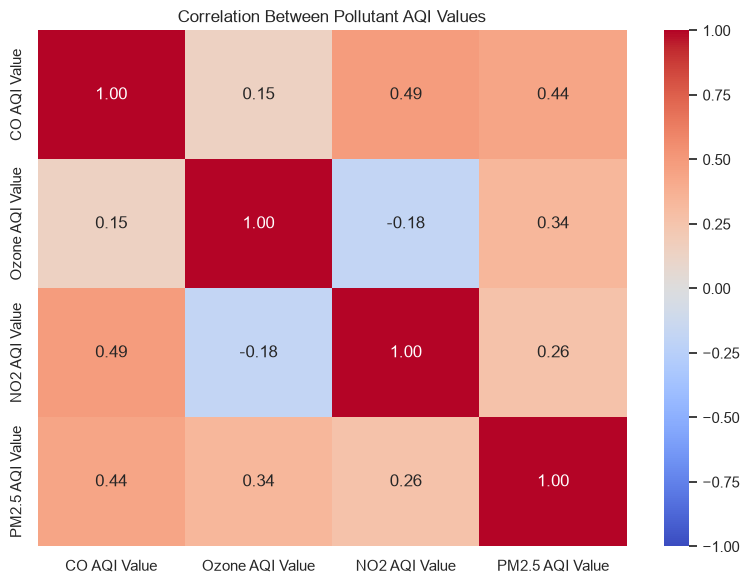

In [6]:
# Pollutant values by AQI category
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} by AQI category")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# Correlation between numerical pollutant features
plt.figure(figsize=(8, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Pollutant AQI Values")
plt.tight_layout()
plt.show()

## 6. Prepare features and target
We intentionally do **not** use `AQI Value`, `AQI Category` (as a feature), city, country, or pollutant category text columns. `AQI Value` is used to derive the target category and would leak the answer. The four numeric pollutant AQI values are the input features.

In [7]:
X = df[FEATURES].copy()
y = df[TARGET].astype(str).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", sorted(y.unique()))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTrain class proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTest class proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

X shape: (23463, 4)
y shape: (23463,)
Classes: ['Good', 'Hazardous', 'Moderate', 'Unhealthy', 'Unhealthy for Sensitive Groups', 'Very Unhealthy']
Training rows: 18770
Testing rows: 4693

Train class proportions:


,proportion
AQI Category,
Good,0.423495
Moderate,0.393447
Unhealthy,0.094885
Unhealthy for Sensitive Groups,0.067821
Very Unhealthy,0.012200
Hazardous,0.008151



Test class proportions:


,proportion
AQI Category,
Good,0.423397
Moderate,0.393352
Unhealthy,0.095035
Unhealthy for Sensitive Groups,0.067760
Very Unhealthy,0.012359
Hazardous,0.008097


## 7. Define baseline and candidate models
All models use a median imputer. Scaling is included for Logistic Regression; tree models do not require feature scaling. `class_weight="balanced"` is used where supported to reduce the impact of class imbalance.

In [8]:
models = {
    "Dummy Baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, min_samples_leaf=2))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                         min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(n_estimators=400, class_weight="balanced",
                                        min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RANDOM_STATE))
    ]),
}
print("Models:", list(models))

Models: ['Dummy Baseline', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting']


## 8. Train models and compare performance
The test set is held back until final evaluation. Model selection uses stratified 5-fold cross-validation on the training set with macro F1, which gives each AQI class equal importance.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
comparison = []
trained_models = {}

for name, pipeline in models.items():
    print(f"Training: {name}")
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    pred = pipeline.predict(X_test)
    comparison.append({
        "Model": name,
        "CV Macro F1 Mean": cv_scores.mean(),
        "CV Macro F1 Std": cv_scores.std(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Test Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Test Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

results = pd.DataFrame(comparison).sort_values("CV Macro F1 Mean", ascending=False).reset_index(drop=True)
display(results.style.format({c: "{:.4f}" for c in results.columns if c != "Model"}))

Training: Dummy Baseline
Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting


,Model,CV Macro F1 Mean,CV Macro F1 Std,Test Accuracy,Test Balanced Accuracy,Test Macro F1,Test Weighted F1
0,Random Forest,0.9899,0.0033,0.9991,0.9840,0.9853,0.9991
1,Decision Tree,0.9850,0.0071,0.9991,0.9921,0.9920,0.9991
2,Extra Trees,0.9761,0.0045,0.9960,0.9693,0.9647,0.9960
3,Hist Gradient Boosting,0.9569,0.0264,0.9962,0.9569,0.9600,0.9961
4,Logistic Regression,0.8659,0.0029,0.9320,0.9135,0.8707,0.9335
5,Dummy Baseline,0.0992,0.0000,0.4234,0.1667,0.0992,0.2519


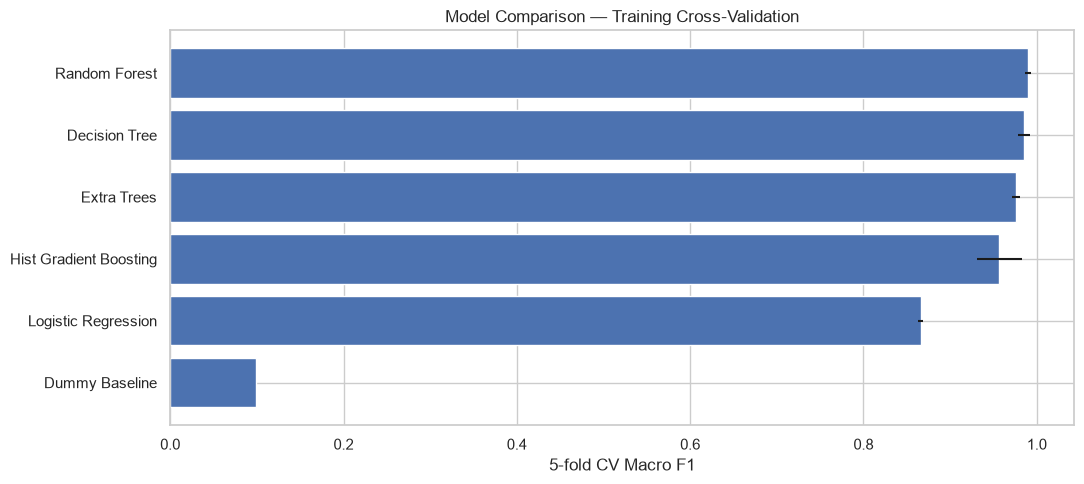

In [10]:
plt.figure(figsize=(11, 5))
plot_df = results.sort_values("CV Macro F1 Mean", ascending=True)
plt.barh(plot_df["Model"], plot_df["CV Macro F1 Mean"], xerr=plot_df["CV Macro F1 Std"])
plt.xlabel("5-fold CV Macro F1")
plt.title("Model Comparison — Training Cross-Validation")
plt.tight_layout()
plt.show()

## 9. Select the best model and evaluate it on the test set

In [11]:
best_name = results.iloc[0]["Model"]
best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro precision:   {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall:      {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1:          {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1:       {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Selected model: Random Forest
Accuracy:          0.9991
Balanced accuracy: 0.9840
Macro precision:   0.9870
Macro recall:      0.9840
Macro F1:          0.9853
Weighted F1:       0.9991

Classification report:
                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00      1987
                     Hazardous       0.97      0.92      0.95        38
                      Moderate       1.00      1.00      1.00      1846
                     Unhealthy       1.00      1.00      1.00       446
Unhealthy for Sensitive Groups       1.00      1.00      1.00       318
                Very Unhealthy       0.95      0.98      0.97        58

                      accuracy                           1.00      4693
                     macro avg       0.99      0.98      0.99      4693
                  weighted avg       1.00      1.00      1.00      4693



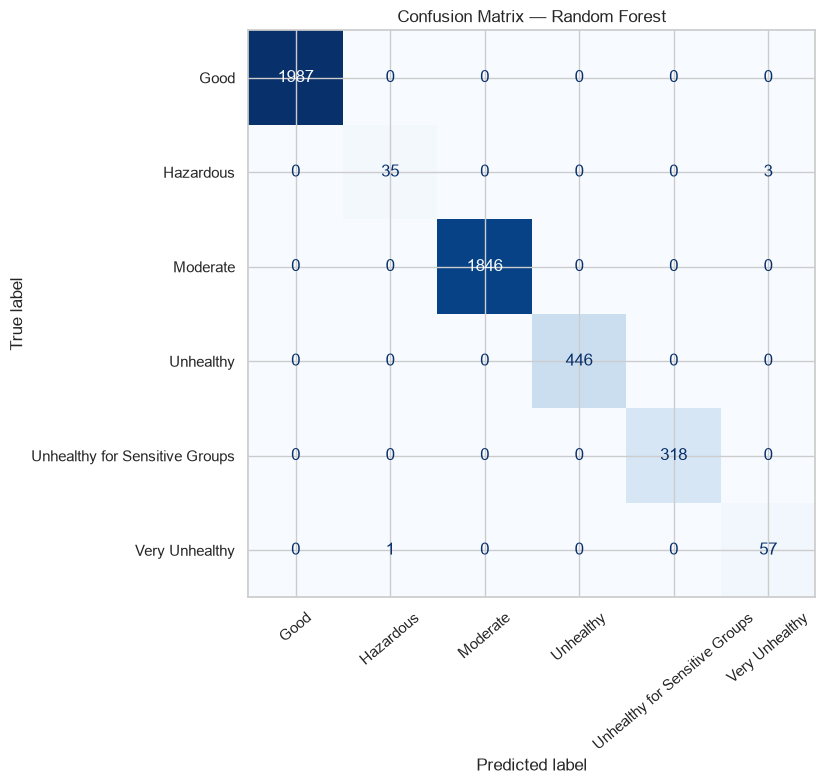

In [12]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=40, colorbar=False, values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 10. Inspect feature importance (when supported)

,importance
PM2.5 AQI Value,0.802762
Ozone AQI Value,0.118276
CO AQI Value,0.061443
NO2 AQI Value,0.017519


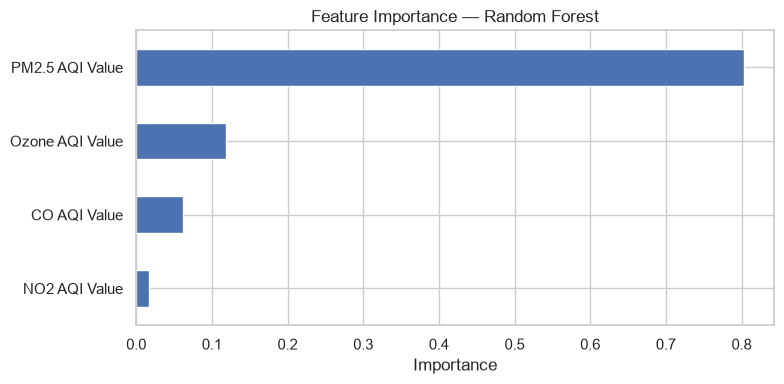

In [13]:
final_estimator = best_model.named_steps["model"]
if hasattr(final_estimator, "feature_importances_"):
    importance = pd.Series(final_estimator.feature_importances_, index=FEATURES).sort_values()
    display(importance.sort_values(ascending=False).to_frame("importance"))
    importance.plot(kind="barh", figsize=(8, 4), title=f"Feature Importance — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
elif hasattr(final_estimator, "coef_"):
    coef = pd.DataFrame(final_estimator.coef_, columns=FEATURES, index=final_estimator.classes_)
    display(coef)
else:
    print("This model does not expose native feature importance.")

## 11. Test a single prediction

In [14]:
# Example values are AQI sub-index values, not raw pollutant concentrations.
sample = pd.DataFrame([{
    "CO AQI Value": 1,
    "Ozone AQI Value": 35,
    "NO2 AQI Value": 3,
    "PM2.5 AQI Value": 65,
}])[FEATURES]
predicted_category = best_model.predict(sample)[0]
print("Input values:")
display(sample)
print("Predicted AQI Category:", predicted_category)
if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample)[0]
    probability_df = pd.DataFrame({"AQI Category": best_model.classes_, "Probability": probabilities})
    display(probability_df.sort_values("Probability", ascending=False).reset_index(drop=True))

Input values:


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
0,1,35,3,65


Predicted AQI Category: Moderate


,AQI Category,Probability
0,Moderate,1.0
1,Good,0.0
2,Hazardous,0.0
3,Unhealthy,0.0
4,Unhealthy for Sensitive Groups,0.0
5,Very Unhealthy,0.0


## 12. Save the model for Streamlit
The exported file contains the complete preprocessing + model pipeline, feature names, target name, and class labels. Streamlit can load this one file directly. The comparison table and metrics are also exported for the dashboard.

In [15]:
OUTPUT_DIR = Path("models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = OUTPUT_DIR / "airguard_best_model.joblib"
RESULTS_PATH = OUTPUT_DIR / "model_comparison.csv"
METRICS_PATH = OUTPUT_DIR / "model_metrics.json"

artifact = {
    "model": best_model,
    "model_name": best_name,
    "features": FEATURES,
    "target": TARGET,
    "classes": [str(x) for x in best_model.classes_],
    "random_state": RANDOM_STATE,
}
joblib.dump(artifact, MODEL_PATH)
results.to_csv(RESULTS_PATH, index=False)
metrics = {
    "model_name": best_name,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
    "macro_precision": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
    "weighted_f1": float(f1_score(y_test, y_pred, average="weighted", zero_division=0)),
}
with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Saved model:", MODEL_PATH.resolve())
print("Saved comparison:", RESULTS_PATH.resolve())
print("Saved metrics:", METRICS_PATH.resolve())

Saved model: D:\python\AirGuard_AI_2_0\models\airguard_best_model.joblib
Saved comparison: D:\python\AirGuard_AI_2_0\models\model_comparison.csv
Saved metrics: D:\python\AirGuard_AI_2_0\models\model_metrics.json


## 13. Reload the saved model and verify it

In [16]:
loaded_artifact = joblib.load(MODEL_PATH)
loaded_model = loaded_artifact["model"]
reloaded_pred = loaded_model.predict(X_test)
print("Reloaded model:", loaded_artifact["model_name"])
print("Predictions identical:", np.array_equal(y_pred, reloaded_pred))
print("Reloaded test accuracy:", accuracy_score(y_test, reloaded_pred))

Reloaded model: Random Forest
Predictions identical: True
Reloaded test accuracy: 0.9991476667376944


In [17]:
import sklearn
import sys

print("Notebook scikit-learn version:", sklearn.__version__)
print("Notebook Python:", sys.executable)

Notebook scikit-learn version: 1.7.2
Notebook Python: C:\Users\pabit\anaconda3\envs\crowdshield\python.exe


In [18]:
# 2.0 / CELL 1 — Advanced imports and output folders
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, matthews_corrcoef,
    cohen_kappa_score
)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

ADVANCED_OUTPUT = Path("outputs/airguard_ai_2_0")
ADVANCED_OUTPUT.mkdir(parents=True, exist_ok=True)
print("Advanced outputs:", ADVANCED_OUTPUT.resolve())
print("Selected model:", best_name)

Advanced outputs: D:\python\AirGuard_AI_2_0\outputs\airguard_ai_2_0
Selected model: Random Forest


## 2. Target dependence and data-quality audit

The dataset includes an overall AQI category and pollutant-specific AQI sub-index categories. This audit measures their agreement and checks whether the model task may be dominated by a single pollutant sub-index. High classification performance must be interpreted in this context.

In [19]:
# 2.0 / CELL 2 — Target dependence audit
audit = df.copy()
audit.columns = audit.columns.astype(str).str.strip()

pm_cat_match = np.nan
pm_value_match = np.nan
if "PM2.5 AQI Category" in audit.columns:
    pm_cat_match = (
        audit[TARGET].astype(str).str.strip()
        == audit["PM2.5 AQI Category"].astype(str).str.strip()
    ).mean()
if "AQI Value" in audit.columns and "PM2.5 AQI Value" in audit.columns:
    pm_value_match = (
        pd.to_numeric(audit["AQI Value"], errors="coerce")
        == pd.to_numeric(audit["PM2.5 AQI Value"], errors="coerce")
    ).mean()

audit_summary = pd.DataFrame({
    "Audit": [
        "Rows after original cleaning",
        "Number of target classes",
        "AQI Category matches PM2.5 AQI Category",
        "AQI Value equals PM2.5 AQI Value"
    ],
    "Result": [
        len(audit), audit[TARGET].nunique(), pm_cat_match, pm_value_match
    ]
})
display(audit_summary)
audit_summary.to_csv(ADVANCED_OUTPUT / "target_dependence_audit.csv", index=False)
print("Target distribution:")
display(audit[TARGET].value_counts().to_frame("Records"))
if pd.notna(pm_cat_match) and pm_cat_match >= 0.90:
    print("CAUTION: AQI category agrees strongly with PM2.5 category. High scores may reflect the dataset's label construction.")

,Audit,Result
0,Rows after original cleaning,23463.000000
1,Number of target classes,6.000000
2,AQI Category matches PM2.5 AQI Category,0.975749
3,AQI Value equals PM2.5 AQI Value,0.783446


Target distribution:


,Records
AQI Category,
Good,9936
Moderate,9231
Unhealthy,2227
Unhealthy for Sensitive Groups,1591
Very Unhealthy,287
Hazardous,191


CAUTION: AQI category agrees strongly with PM2.5 category. High scores may reflect the dataset's label construction.


## 3. Comprehensive evaluation

Accuracy is accompanied by balanced accuracy, macro/weighted precision, recall and F1, Matthews correlation coefficient and Cohen's kappa. Macro metrics give each class equal weight and are useful when category counts are imbalanced.

,Value
model_name,Random Forest
accuracy,0.999148
balanced_accuracy,0.983969
macro_precision,0.987037
macro_recall,0.983969
macro_f1,0.985341
weighted_precision,0.999157
weighted_recall,0.999148
weighted_f1,0.999143
matthews_corrcoef,0.998693


,precision,recall,f1-score,support
Good,1.000000,1.000000,1.000000,1987.000000
Hazardous,0.972222,0.921053,0.945946,38.000000
Moderate,1.000000,1.000000,1.000000,1846.000000
Unhealthy,1.000000,1.000000,1.000000,446.000000
Unhealthy for Sensitive Groups,1.000000,1.000000,1.000000,318.000000
Very Unhealthy,0.950000,0.982759,0.966102,58.000000
accuracy,0.999148,0.999148,0.999148,0.999148
macro avg,0.987037,0.983969,0.985341,4693.000000
weighted avg,0.999157,0.999148,0.999143,4693.000000


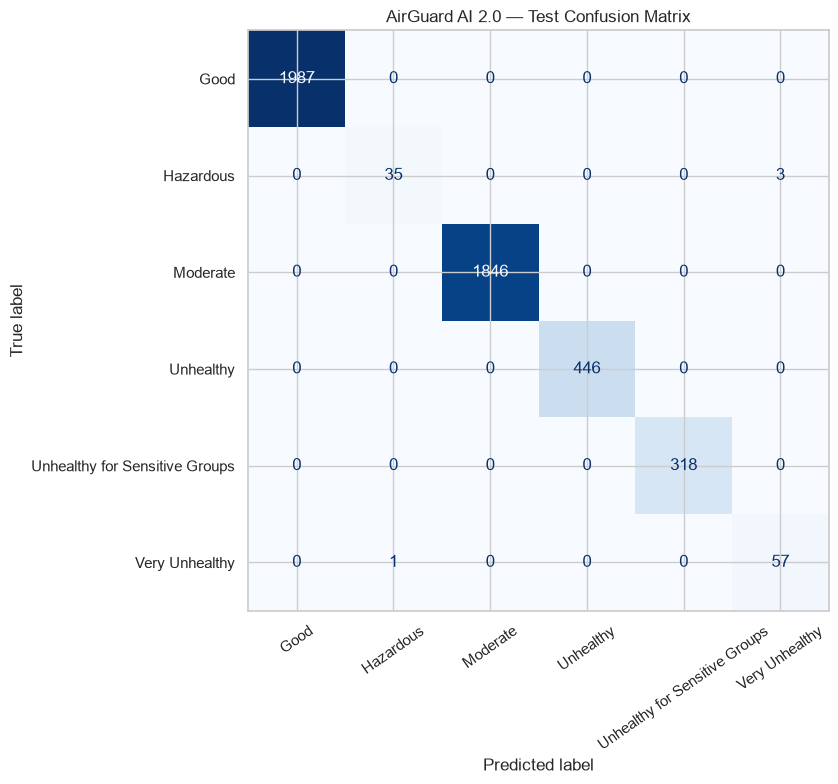

In [20]:
# 2.0 / CELL 3 — Comprehensive held-out evaluation
advanced_pred = best_model.predict(X_test)
advanced_metrics = {
    "model_name": str(best_name),
    "accuracy": float(accuracy_score(y_test, advanced_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, advanced_pred)),
    "macro_precision": float(precision_score(y_test, advanced_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_test, advanced_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_test, advanced_pred, average="macro", zero_division=0)),
    "weighted_precision": float(precision_score(y_test, advanced_pred, average="weighted", zero_division=0)),
    "weighted_recall": float(recall_score(y_test, advanced_pred, average="weighted", zero_division=0)),
    "weighted_f1": float(f1_score(y_test, advanced_pred, average="weighted", zero_division=0)),
    "matthews_corrcoef": float(matthews_corrcoef(y_test, advanced_pred)),
    "cohen_kappa": float(cohen_kappa_score(y_test, advanced_pred))
}
display(pd.DataFrame([advanced_metrics]).T.rename(columns={0:"Value"}))
class_report = pd.DataFrame(classification_report(
    y_test, advanced_pred, output_dict=True, zero_division=0
)).T
display(class_report)
class_report.to_csv(ADVANCED_OUTPUT / "class_wise_metrics.csv")

class_labels = sorted(pd.Series(y_test).astype(str).unique())
cm = confusion_matrix(y_test, advanced_pred, labels=class_labels)
fig, ax = plt.subplots(figsize=(10, 8))
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(
    ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False
)
ax.set_title("AirGuard AI 2.0 — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(ADVANCED_OUTPUT / "confusion_matrix.png", dpi=220, bbox_inches="tight")
plt.show()
with open(ADVANCED_OUTPUT / "evaluation_metrics.json", "w") as f:
    json.dump(advanced_metrics, f, indent=4)

## 4. Model-agnostic permutation importance

This measures the reduction in held-out macro F1 when each feature is shuffled. It is a model-dependence measure, not evidence of causation.

,Feature,Mean decrease in Macro F1,Standard deviation
3,PM2.5 AQI Value,0.758679,0.003931
1,Ozone AQI Value,0.081001,0.003234
0,CO AQI Value,0.010630,0.003146
2,NO2 AQI Value,0.005290,0.003028


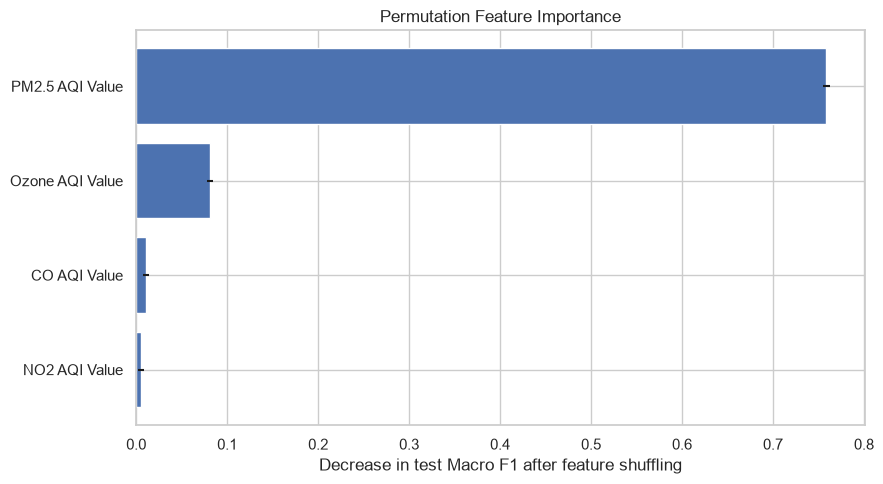

In [21]:
# 2.0 / CELL 4 — Permutation importance
perm = permutation_importance(
    best_model, X_test, y_test, scoring="f1_macro",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
permutation_df = pd.DataFrame({
    "Feature": FEATURES,
    "Mean decrease in Macro F1": perm.importances_mean,
    "Standard deviation": perm.importances_std
}).sort_values("Mean decrease in Macro F1", ascending=False)
display(permutation_df)
permutation_df.to_csv(ADVANCED_OUTPUT / "permutation_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 5))
ordered = permutation_df.sort_values("Mean decrease in Macro F1")
ax.barh(ordered["Feature"], ordered["Mean decrease in Macro F1"],
        xerr=ordered["Standard deviation"])
ax.set_xlabel("Decrease in test Macro F1 after feature shuffling")
ax.set_title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig(ADVANCED_OUTPUT / "permutation_importance.png", dpi=220, bbox_inches="tight")
plt.show()

## 5. Unsupervised pollution-pattern anomaly detection

Isolation Forest flags unusual combinations of pollutant AQI sub-index values. An anomaly is not automatically a pollution emergency; it is a statistical outlier that should be investigated.

In [22]:
# 2.0 / CELL 5 — Isolation Forest anomaly detection
anomaly_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("isolation_forest", IsolationForest(
        n_estimators=250, contamination=0.03,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
anomaly_pipeline.fit(X)
anomaly_labels = anomaly_pipeline.predict(X)  # -1 = anomaly, 1 = inlier
anomaly_scores = anomaly_pipeline.decision_function(X)
anomaly_results = df.copy()
anomaly_results["Anomaly Flag"] = np.where(anomaly_labels == -1, "Anomaly", "Normal")
anomaly_results["Anomaly Score"] = anomaly_scores
print("Anomaly count:", int((anomaly_labels == -1).sum()))
print("Anomaly rate:", f"{(anomaly_labels == -1).mean():.2%}")
display(anomaly_results.loc[anomaly_results["Anomaly Flag"] == "Anomaly"].head(15))
anomaly_results.to_csv(ADVANCED_OUTPUT / "anomaly_detection_results.csv", index=False)
anomaly_pipeline_path = Path("models/airguard_anomaly_detector.joblib")
import joblib
joblib.dump(anomaly_pipeline, anomaly_pipeline_path)

Anomaly count: 704
Anomaly rate: 3.00%


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category,Anomaly Flag,Anomaly Score
43,India,Darbhanga,247,Very Unhealthy,3,Good,162,Unhealthy,1,Good,247,Very Unhealthy,Anomaly,-0.002454
77,China,Hangzhou,203,Very Unhealthy,5,Good,203,Very Unhealthy,5,Good,151,Unhealthy,Anomaly,-0.049753
131,Viet Nam,Tuyen Quang,167,Unhealthy,4,Good,167,Unhealthy,1,Good,107,Unhealthy for Sensitive Groups,Anomaly,-0.001255
137,United States of America,Willowbrook,126,Unhealthy for Sensitive Groups,4,Good,3,Good,36,Good,126,Unhealthy for Sensitive Groups,Anomaly,-0.036355
166,China,Fuzhou,168,Unhealthy,3,Good,168,Unhealthy,5,Good,99,Moderate,Anomaly,-0.004812
239,India,Afzalgarh,198,Unhealthy,4,Good,198,Unhealthy,3,Good,188,Unhealthy,Anomaly,-0.034969
276,Pakistan,Bahawalnagar,500,Hazardous,1,Good,38,Good,1,Good,466,Hazardous,Anomaly,-0.003229
277,South Africa,Balfour,380,Hazardous,31,Good,1,Good,26,Good,380,Hazardous,Anomaly,-0.159753
278,South Africa,Ballitoville,222,Very Unhealthy,12,Good,5,Good,14,Good,222,Very Unhealthy,Anomaly,-0.081503
288,India,Bazpur,182,Unhealthy,5,Good,170,Unhealthy,5,Good,182,Unhealthy,Anomaly,-0.031933


['models\\airguard_anomaly_detector.joblib']

## 6. SHAP explainability

The SHAP section attempts a model-agnostic KernelExplainer on a small background and sample to control runtime. If SHAP is not installed or incompatible, permutation importance remains available and the notebook records the issue.

In [23]:
# 2.0 / CELL 6 — SHAP (bounded computation with graceful fallback)
shap_status = "Not run"
try:
    import shap
    if not hasattr(best_model, "predict_proba"):
        raise RuntimeError("Selected estimator does not expose predict_proba.")
    background_df = X_train.sample(min(30, len(X_train)), random_state=RANDOM_STATE)[FEATURES]
    explain_df = X_test.sample(min(15, len(X_test)), random_state=RANDOM_STATE)[FEATURES]
    predicted_label = str(best_model.predict(explain_df.iloc[[0]])[0])
    class_idx = list(best_model.classes_).index(predicted_label)

    def predict_selected_probability(arr):
        arr_df = pd.DataFrame(arr, columns=FEATURES)
        return best_model.predict_proba(arr_df)[:, class_idx]

    kernel_explainer = shap.KernelExplainer(
        predict_selected_probability, background_df.to_numpy()
    )
    shap_values = kernel_explainer.shap_values(
        explain_df.to_numpy(), nsamples=80
    )
    shap_array = np.asarray(shap_values)
    if shap_array.ndim == 3:
        shap_array = shap_array[0]
    if shap_array.ndim == 1:
        shap_array = shap_array.reshape(1, -1)
    mean_abs = np.abs(shap_array).mean(axis=0)
    shap_importance_df = pd.DataFrame({
        "Feature": FEATURES, "Mean absolute SHAP": mean_abs
    }).sort_values("Mean absolute SHAP", ascending=False)
    display(shap_importance_df)
    shap_importance_df.to_csv(ADVANCED_OUTPUT / "shap_importance.csv", index=False)
    plt.figure(figsize=(8, 4))
    plt.barh(shap_importance_df["Feature"][::-1], shap_importance_df["Mean absolute SHAP"][::-1])
    plt.title(f"SHAP importance for predicted class: {predicted_label}")
    plt.xlabel("Mean absolute SHAP value")
    plt.tight_layout()
    plt.savefig(ADVANCED_OUTPUT / "shap_importance.png", dpi=220, bbox_inches="tight")
    plt.show()
    shap_status = "Completed"
except Exception as shap_error:
    shap_status = f"Unavailable: {type(shap_error).__name__}: {shap_error}"
    print(shap_status)
    print("Use permutation_importance as the supported model-agnostic explanation.")

Unavailable: ModuleNotFoundError: No module named 'shap'
Use permutation_importance as the supported model-agnostic explanation.


## 7. 3D pollutant relationship exploration

A 3D scatter plot can reveal relationships among pollutant AQI sub-indices. It is an exploratory visualization, not a geographic map.

In [24]:
# 2.0 / CELL 7 — 3D pollutant visualization
import plotly.express as px
sample_3d = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)
fig = px.scatter_3d(
    sample_3d,
    x="PM2.5 AQI Value", y="Ozone AQI Value", z="CO AQI Value",
    color=TARGET, hover_data=["City"] if "City" in sample_3d.columns else None,
    opacity=0.65, title="3D Pollutant AQI Sub-index Relationship",
    template="plotly_dark"
)
fig.update_layout(height=700, paper_bgcolor="rgba(0,0,0,0)")
fig.show()

## 8. Export reproducible AirGuard AI 2.0 artifacts

This saves the anomaly detector and an advanced metrics summary. The original best model remains intact.

In [25]:
# 2.0 / CELL 8 — Export final Day 1 bundle
summary_2 = {
    "project": "AirGuard AI 2.0",
    "selected_classifier": str(best_name),
    "features": list(FEATURES),
    "target": str(TARGET),
    "metrics": advanced_metrics,
    "pm25_category_agreement": float(pm_cat_match) if pd.notna(pm_cat_match) else None,
    "aqi_equals_pm25_value_fraction": float(pm_value_match) if pd.notna(pm_value_match) else None,
    "anomaly_count": int((anomaly_labels == -1).sum()),
    "anomaly_fraction": float((anomaly_labels == -1).mean()),
    "shap_status": shap_status,
    "limitations": [
        "Classification predicts the dataset's existing AQI category, not future AQI.",
        "The supplied dataset has no timestamp for training a temporal forecast model.",
        "The supplied dataset has no trusted latitude/longitude for precise spatial hotspot mapping.",
        "Anomaly flags are statistical outliers, not official pollution alerts."
    ]
}
with open(ADVANCED_OUTPUT / "airguard_ai_2_0_summary.json", "w") as f:
    json.dump(summary_2, f, indent=4)
print("AIRGUARD AI 2.0 NOTEBOOK CHAPTER COMPLETE")
print("Outputs:", sorted(p.name for p in ADVANCED_OUTPUT.iterdir()))

AIRGUARD AI 2.0 NOTEBOOK CHAPTER COMPLETE
Outputs: ['airguard_ai_2_0_summary.json', 'anomaly_detection_results.csv', 'class_wise_metrics.csv', 'confusion_matrix.png', 'evaluation_metrics.json', 'permutation_importance.csv', 'permutation_importance.png', 'target_dependence_audit.csv']
